<a href="https://colab.research.google.com/github/officialinmailbox-art/Assignment_Bits/blob/DNN_Assignment/2026AJ05499_DNN_Assignment/Problem2/problem2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problem 2 – Transformer from scratch

Runs top to bottom (Restart and Run All). Outputs: `figures/`, `generated_samples.txt` and the shared `../results.csv`.
`nn.MultiheadAttention` / `nn.Transformer*` are **not** used; `F.scaled_dot_product_attention` is used only inside a test.

**Before the final run:** set `QUICK_RUN = False` and your variant's `SEEDS`.

**Assumptions (state these in the report):**
- The instructor's 3-token example was not provided, so a hand-checkable example with explicit numbers is used; replace `Q, K, V` in that cell if you have the official values.
- Task A: patch size 8 (16 patches + CLS), 2 encoder layers, AdamW lr 5e-4, same epoch budget as Problem 1, model selected on validation macro-F1.
- Task B: AdamW lr 1e-3 with 100-step warm-up and cosine decay; validation loss is measured on the whole last 10% of the text using non-overlapping 128-character windows.

In [ ]:
import os, math, time, copy, random, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score

warnings.filterwarnings("ignore")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| torch", torch.__version__)

# ---- True only for a smoke test; the final run must use False ----
QUICK_RUN = False

SEEDS = [11, 22, 33]                 # YOUR variant's three seeds
# Language model size. Without a GPU use LM_D_MODEL = 64, LM_LAYERS = 2 and say so in the README.
CONTEXT_LENGTH, LM_D_MODEL, LM_HEADS, LM_LAYERS, LM_D_FF = 128, 128, 4, 4, 512
LM_DROPOUT, LM_LR = 0.1, 1e-3
# HAR encoder
HAR_D_MODEL, HAR_HEADS, HAR_LAYERS, HAR_D_FF, HAR_DROPOUT, HAR_PATCH, HAR_LR = 128, 4, 2, 512, 0.1, 8, 5e-4
HAR_BATCH_SIZE = 128

if QUICK_RUN:
    SEEDS = SEEDS[:1]; HAR_EPOCHS = 2; LM_EPOCHS = 2; LM_STEPS = 20; ABL_EPOCHS = 1; LM_BATCH = 16
else:
    HAR_EPOCHS = 20; LM_EPOCHS = 12; LM_STEPS = 250; ABL_EPOCHS = 4; LM_BATCH = 64

ROOT = ".." if os.path.basename(os.path.abspath(os.getcwd())) in ("problem1", "problem2") else "."
FIG_DIR, DATA_DIR = "figures", "data"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(DATA_DIR, exist_ok=True)
RESULTS_CSV = os.path.join(ROOT, "results.csv")
CSV_COLUMNS = ["problem", "model", "seed", "seq_len", "test_acc", "macro_f1", "test_mse",
               "params", "sec_per_epoch", "val_loss_nats", "bits_per_char", "notes"]

def reset_results(prefix):
    if os.path.exists(RESULTS_CSV):
        df = pd.read_csv(RESULTS_CSV).reindex(columns=CSV_COLUMNS)
        df[~df["problem"].astype(str).str.startswith(prefix)].to_csv(RESULTS_CSV, index=False)

def append_result(**row):
    new = pd.DataFrame([{c: row.get(c, np.nan) for c in CSV_COLUMNS}], columns=CSV_COLUMNS)
    if os.path.exists(RESULTS_CSV):
        old = pd.read_csv(RESULTS_CSV).reindex(columns=CSV_COLUMNS)
        if len(old):
            new = pd.concat([old, new], ignore_index=True)
    new.to_csv(RESULTS_CSV, index=False)

reset_results("P2")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def count_parameters(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight"); plt.show()

Device: cuda | torch 2.14.1+cu130


##  1 – Scaled dot-product attention with optional mask

In [ ]:
def scaled_dot_product_attention(Q, K, V, mask=None, dropout_p=0.0, training=False):
    """Q (B,H,Tq,D), K (B,H,Tk,D), V (B,H,Tk,Dv); mask broadcastable to (B,H,Tq,Tk), True = may attend.
    Returns output (B,H,Tq,Dv) and weights (B,H,Tq,Tk)."""
    d_k = Q.size(-1)
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d_k)              # (B,H,Tq,D)@(B,H,D,Tk) -> (B,H,Tq,Tk)
    if mask is not None:
        scores = scores.masked_fill(~mask.to(torch.bool), float("-inf"))
    weights = torch.softmax(scores, dim=-1)                         # each row sums to 1
    if dropout_p > 0 and training:
        weights = F.dropout(weights, p=dropout_p, training=True)
    return weights @ V, weights                                     # (B,H,Tq,Tk)@(B,H,Tk,Dv) -> (B,H,Tq,Dv)

In [ ]:
# ---- unit tests ----
torch.manual_seed(7)
Q, K, V = (torch.randn(2, 3, 5, 8) for _ in range(3))
out, w = scaled_dot_product_attention(Q, K, V)
assert torch.allclose(w.sum(-1), torch.ones(2, 3, 5), atol=1e-6)                       # rows sum to 1
assert torch.allclose(out, F.scaled_dot_product_attention(Q, K, V), atol=1e-5)          # matches the library
causal = torch.tril(torch.ones(5, 5, dtype=torch.bool))
out_c, w_c = scaled_dot_product_attention(Q, K, V, causal)
assert torch.all(torch.triu(w_c, diagonal=1) == 0)                                      # zero weight on future positions
assert torch.allclose(out_c, F.scaled_dot_product_attention(Q, K, V, is_causal=True), atol=1e-5)
assert torch.allclose(w_c.sum(-1), torch.ones(2, 3, 5), atol=1e-6)
print("Scaled dot-product attention tests PASSED")

Scaled dot-product attention tests PASSED


In [ ]:
# ---- hand-checkable 3-token example (d_k = 2; replace Q,K,V with the instructor's values if different) ----
Q3 = torch.tensor([[1., 0.], [0., 1.], [1., 1.]]); K3 = Q3.clone()
V3 = torch.tensor([[1., 0.], [0., 2.], [2., 1.]])
out3, w3 = scaled_dot_product_attention(Q3[None, None], K3[None, None], V3[None, None])
out3, w3 = out3[0, 0], w3[0, 0]
print("scores = Q K^T / sqrt(2) =\n", (Q3 @ K3.T / math.sqrt(2)).numpy().round(4))
print("weights =\n", w3.numpy().round(4)); print("output =\n", out3.numpy().round(4))
# By hand: Q K^T = [[1,0,1],[0,1,1],[1,1,2]];  /sqrt2 -> [[.7071,0,.7071],[0,.7071,.7071],[.7071,.7071,1.4142]]
# row 1: e^.7071=2.0281, e^0=1  -> [2.0281,1,2.0281]/5.0562 = [.4011,.1978,.4011]
# row 3: e^1.4142=4.1133        -> [2.0281,2.0281,4.1133]/8.1695 = [.2483,.2483,.5035]
# output row 1 = .4011*[1,0] + .1978*[0,2] + .4011*[2,1] = [1.2033, 0.7967]
hand_w = torch.tensor([[.4011, .1978, .4011], [.1978, .4011, .4011], [.2483, .2483, .5035]])
hand_o = torch.tensor([[1.2033, .7967], [1.0, 1.2033], [1.2552, 1.0]])
assert torch.allclose(w3, hand_w, atol=5e-4) and torch.allclose(out3, hand_o, atol=5e-4)
print("Hand calculation and code agree")

scores = Q K^T / sqrt(2) =
 [[0.7071 0.     0.7071]
 [0.     0.7071 0.7071]
 [0.7071 0.7071 1.4142]]
weights =
 [[0.4011 0.1978 0.4011]
 [0.1978 0.4011 0.4011]
 [0.2483 0.2483 0.5035]]
output =
 [[1.2033 0.7967]
 [1.     1.2033]
 [1.2552 1.    ]]
Hand calculation and code agree


## 2 – Multi-head attention, positional encoding, pre-LN encoder block

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model=128, num_heads=4, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.H, self.Dh = num_heads, d_model // num_heads
        self.W_Q, self.W_K, self.W_V, self.W_O = (nn.Linear(d_model, d_model) for _ in range(4))
        self.attn_p, self.out_drop = dropout, nn.Dropout(dropout)
    def forward(self, x, mask=None, return_attention=False):
        B, T, C = x.shape                                                       # x (B,T,C)
        split = lambda t: t.view(B, T, self.H, self.Dh).transpose(1, 2)         # (B,T,C) -> (B,H,T,Dh)
        Q, K, V = split(self.W_Q(x)), split(self.W_K(x)), split(self.W_V(x))
        o, w = scaled_dot_product_attention(Q, K, V, mask, self.attn_p, self.training)   # o (B,H,T,Dh), w (B,H,T,T)
        o = o.transpose(1, 2).contiguous().view(B, T, C)                        # merge heads -> (B,T,C)
        o = self.out_drop(self.W_O(o))
        return (o, w) if return_attention else o

class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=4096):
        super().__init__()
        pos = torch.arange(max_len, dtype=torch.float32)[:, None]
        div = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(1, max_len, d_model)
        pe[0, :, 0::2] = torch.sin(pos * div); pe[0, :, 1::2] = torch.cos(pos * div[: d_model // 2])
        self.register_buffer("pe", pe)
    def forward(self, x):                                                       # (B,T,C) -> (B,T,C)
        return x + self.pe[:, : x.size(1)]

class PositionalEncoding(nn.Module):
    """mode: 'none' | 'sinusoidal' | 'learned'"""
    def __init__(self, mode, d_model, max_len=4096):
        super().__init__()
        self.mode = mode
        if mode == "sinusoidal": self.enc = SinusoidalPositionalEncoding(d_model, max_len)
        elif mode == "learned": self.emb = nn.Embedding(max_len, d_model)
        elif mode != "none": raise ValueError(mode)
    def forward(self, x):
        if self.mode == "sinusoidal": return self.enc(x)
        if self.mode == "learned": return x + self.emb(torch.arange(x.size(1), device=x.device))[None]
        return x

class EncoderBlock(nn.Module):
    """Pre-LayerNorm block: x + MHA(LN(x)), then x + FFN(LN(x)); FFN width d_ff (= 4d)."""
    def __init__(self, d_model=128, num_heads=4, d_ff=512, dropout=0.1):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Dropout(dropout), nn.Linear(d_ff, d_model))
        self.drop = nn.Dropout(dropout)
    def forward(self, x, mask=None, return_attention=False):
        a, w = self.attn(self.norm1(x), mask, return_attention=True)
        x = x + self.drop(a)
        x = x + self.drop(self.ffn(self.norm2(x)))
        return (x, w) if return_attention else x

In [ ]:
# ---- unit tests: shapes, causal MHA, sinusoidal PE, parameter count ----

torch.manual_seed(1)
mha = MultiHeadAttention(32, 4, dropout=0.0).eval()
xs = torch.randn(2, 7, 32)
y, w = mha(xs, return_attention=True)
assert y.shape == (2, 7, 32) and w.shape == (2, 4, 7, 7) and torch.allclose(w.sum(-1), torch.ones(2, 4, 7), atol=1e-6)
_, wc = mha(xs, torch.tril(torch.ones(7, 7, dtype=torch.bool)), return_attention=True)
assert torch.all(torch.triu(wc, 1) == 0)

pe = SinusoidalPositionalEncoding(16, 50).pe[0]
assert torch.allclose(pe[0, 0::2], torch.zeros(8)) and torch.allclose(pe[0, 1::2], torch.ones(8))     # position 0: sin=0, cos=1
assert torch.allclose(pe[3, 0], torch.sin(torch.tensor(3.0)), atol=1e-6)

d, d_ff = 128, 512
blk = EncoderBlock(d, 4, d_ff, 0.1)
assert blk(torch.randn(3, 20, d)).shape == (3, 20, d)
w_formula = 4 * d * d + 2 * d * d_ff                                        # attention W_Q,W_K,W_V,W_O + FFN
w_code = sum(p.numel() for n, p in blk.named_parameters() if p.ndim == 2)
bias_code = sum(p.numel() for n, p in blk.named_parameters() if n.endswith("bias") and "norm" not in n)
ln_code = sum(p.numel() for n, p in blk.named_parameters() if "norm" in n)
print(f"weights: formula {w_formula} | code {w_code}\nlinear biases: 4d + d_ff + d = {4*d + d_ff + d} | code {bias_code}"
      f"\nLayerNorm (2 norms x (gamma+beta) x d) = {4*d} | code {ln_code}\ntotal = {sum(p.numel() for p in blk.parameters())}")
assert w_formula == w_code == 196_608
assert bias_code == 4 * d + d_ff + d == 1152 and ln_code == 4 * d == 512
assert sum(p.numel() for p in blk.parameters()) == 196_608 + 1152 + 512 == 198_272
print("Multi-head attention / encoder block tests PASSED")

weights: formula 196608 | code 196608
linear biases: 4d + d_ff + d = 1152 | code 1152
LayerNorm (2 norms x (gamma+beta) x d) = 512 | code 512
total = 198272
Multi-head attention / encoder block tests PASSED


## A – Encoder classifier on HAR
Same data pipeline as Problem 1 (subject-wise validation split per seed, training-only normalisation).

HAR-TF pos=none s11 ep 1/20 train 0.2912 val 0.4697 F1 0.9033
HAR-TF pos=none s11 ep 5/20 train 0.0662 val 0.6421 F1 0.8572
HAR-TF pos=none s11 ep 10/20 train 0.0408 val 0.5789 F1 0.8974
HAR-TF pos=none s11 ep 15/20 train 0.0299 val 0.6522 F1 0.9058
HAR-TF pos=none s11 ep 20/20 train 0.0186 val 0.7356 F1 0.9082
HAR-TF pos=none s22 ep 1/20 train 0.3445 val 0.1226 F1 0.9583
HAR-TF pos=none s22 ep 5/20 train 0.1166 val 0.1098 F1 0.9596
HAR-TF pos=none s22 ep 10/20 train 0.0747 val 0.1612 F1 0.9500
HAR-TF pos=none s22 ep 15/20 train 0.0380 val 0.0963 F1 0.9721
HAR-TF pos=none s22 ep 20/20 train 0.0282 val 0.1225 F1 0.9642
HAR-TF pos=none s33 ep 1/20 train 0.3603 val 0.2595 F1 0.8998
HAR-TF pos=none s33 ep 5/20 train 0.1044 val 0.2660 F1 0.9104
HAR-TF pos=none s33 ep 10/20 train 0.0762 val 0.3125 F1 0.9141
HAR-TF pos=none s33 ep 15/20 train 0.0458 val 0.3816 F1 0.9083
HAR-TF pos=none s33 ep 20/20 train 0.0309 val 0.2976 F1 0.9266
HAR-TF pos=sinusoidal s11 ep 1/20 train 0.4987 val 0.2739 F1 

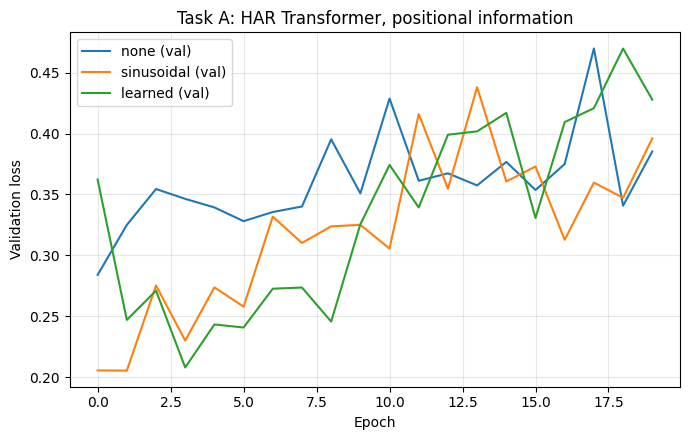

In [ ]:
HAR_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
HAR_BASE = os.path.join(DATA_DIR, "UCI HAR Dataset")
HAR_CHANNELS = ["body_acc_x", "body_acc_y", "body_acc_z", "body_gyro_x", "body_gyro_y", "body_gyro_z",
                "total_acc_x", "total_acc_y", "total_acc_z"]

def download_har():
    need = os.path.join(HAR_BASE, "train", "Inertial Signals", "body_acc_x_train.txt")
    if os.path.isfile(need): return
    outer = os.path.join(DATA_DIR, "har.zip")
    if not os.path.exists(outer): urllib.request.urlretrieve(HAR_URL, outer)
    zipfile.ZipFile(outer).extractall(DATA_DIR)
    inner = os.path.join(DATA_DIR, "UCI HAR Dataset.zip")
    if not os.path.isfile(need) and os.path.isfile(inner): zipfile.ZipFile(inner).extractall(DATA_DIR)
    assert os.path.isfile(need), "HAR extraction failed"

def load_har_split(split):
    sig = [np.loadtxt(os.path.join(HAR_BASE, split, "Inertial Signals", f"{c}_{split}.txt"), dtype=np.float32) for c in HAR_CHANNELS]
    X = np.stack(sig, axis=-1)                                                                     # (N,128,9)
    y = np.loadtxt(os.path.join(HAR_BASE, split, f"y_{split}.txt"), dtype=np.int64) - 1
    s = np.loadtxt(os.path.join(HAR_BASE, split, f"subject_{split}.txt"), dtype=np.int64)
    return X, y, s

download_har()
HAR_RAW = {sp: load_har_split(sp) for sp in ("train", "test")}

def make_har_loaders(seed):
    X_all, y_all, s_all = HAR_RAW["train"]; X_te, y_te, s_te = HAR_RAW["test"]
    val_subjects = np.random.default_rng(seed).choice(np.unique(s_all), 4, replace=False)
    is_val = np.isin(s_all, val_subjects)
    Xtr = X_all[~is_val]
    mean = Xtr.mean(axis=(0, 1), keepdims=True); std = Xtr.std(axis=(0, 1), keepdims=True); std[std < 1e-8] = 1.0
    norm = lambda X: ((X - mean) / std).astype(np.float32)
    dl = lambda X, y, sh: DataLoader(TensorDataset(torch.from_numpy(norm(X)), torch.from_numpy(y)), batch_size=HAR_BATCH_SIZE, shuffle=sh)
    assert set(val_subjects).isdisjoint(s_te)
    return {"train": dl(Xtr, y_all[~is_val], True), "val": dl(X_all[is_val], y_all[is_val], False), "test": dl(X_te, y_te, False)}

class HARTransformer(nn.Module):
    def __init__(self, pos_mode="sinusoidal", patch=HAR_PATCH, d_model=HAR_D_MODEL, heads=HAR_HEADS,
                 layers=HAR_LAYERS, d_ff=HAR_D_FF, dropout=HAR_DROPOUT, in_ch=9, n_classes=6):
        super().__init__()
        self.patch = patch
        self.embed = nn.Linear(in_ch * patch, d_model)
        self.cls = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        self.pos = PositionalEncoding(pos_mode, d_model, max_len=256)
        self.blocks = nn.ModuleList([EncoderBlock(d_model, heads, d_ff, dropout) for _ in range(layers)])
        self.norm = nn.LayerNorm(d_model); self.head = nn.Linear(d_model, n_classes)
    def forward(self, x):                                           # x (B,128,9)
        B, T, C = x.shape
        x = self.embed(x.reshape(B, T // self.patch, self.patch * C))      # (B,16,d)
        x = self.pos(torch.cat([self.cls.expand(B, -1, -1), x], dim=1))    # (B,17,d), CLS first
        for blk in self.blocks: x = blk(x)
        return self.head(self.norm(x[:, 0]))                               # classify from CLS

@torch.no_grad()
def eval_cls(model, loader):
    model.eval(); P, Tt, tot, n = [], [], 0.0, 0
    for X, y in loader:
        X, y = X.to(DEVICE), y.to(DEVICE); o = model(X)
        tot += F.cross_entropy(o, y).item() * len(y); n += len(y); P.append(o.argmax(1).cpu().numpy()); Tt.append(y.cpu().numpy())
    P, Tt = np.concatenate(P), np.concatenate(Tt)
    return dict(loss=tot / n, acc=accuracy_score(Tt, P), f1=f1_score(Tt, P, average="macro", zero_division=0))

def train_har(loaders, mode, seed):
    set_seed(seed)
    model = HARTransformer(mode).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=HAR_LR)
    best_f1, best_state, secs, tr_hist, va_hist = -1, None, [], [], []
    for ep in range(HAR_EPOCHS):
        model.train(); t0 = time.perf_counter(); tot, n = 0.0, 0
        for X, y in loaders["train"]:
            X, y = X.to(DEVICE), y.to(DEVICE)
            loss = F.cross_entropy(model(X), y)
            opt.zero_grad(set_to_none=True); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot += loss.item() * len(y); n += len(y)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        secs.append(time.perf_counter() - t0); tr_hist.append(tot / n)
        va = eval_cls(model, loaders["val"]); va_hist.append(va["loss"])
        if va["f1"] > best_f1: best_f1, best_state = va["f1"], copy.deepcopy(model.state_dict())
        if ep == 0 or (ep + 1) % 5 == 0: print(f"HAR-TF pos={mode} s{seed} ep {ep+1}/{HAR_EPOCHS} train {tr_hist[-1]:.4f} val {va['loss']:.4f} F1 {va['f1']:.4f}")
    model.load_state_dict(best_state)
    te = eval_cls(model, loaders["test"])
    append_result(problem="P2_TaskA", model=f"Transformer_pos_{mode}", seed=seed, seq_len=128, test_acc=te["acc"], macro_f1=te["f1"],
                  params=count_parameters(model), sec_per_epoch=float(np.mean(secs)),
                  notes=f"patch={HAR_PATCH}; d={HAR_D_MODEL}; heads={HAR_HEADS}; layers={HAR_LAYERS}; epochs={HAR_EPOCHS}; adamw {HAR_LR}")
    return dict(mode=mode, seed=seed, acc=te["acc"], f1=te["f1"], params=count_parameters(model), sec=float(np.mean(secs)), tr=tr_hist, va=va_hist)

HAR_LOADERS = {s: make_har_loaders(s) for s in SEEDS}
A_runs = [train_har(HAR_LOADERS[s], m, s) for m in ["none", "sinusoidal", "learned"] for s in SEEDS]
A_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("tr", "va")} for r in A_runs])
g = A_df.groupby("mode")
A_table = pd.DataFrame({"test acc (mean ± std)": g["acc"].agg(lambda s: f"{s.mean():.4f} ± {s.std(ddof=1):.4f}"),
                        "macro-F1 (mean ± std)": g["f1"].agg(lambda s: f"{s.mean():.4f} ± {s.std(ddof=1):.4f}"),
                        "params": g["params"].first(), "sec/epoch": g["sec"].mean().round(3)}).loc[["none", "sinusoidal", "learned"]]
print("\nTask A: positional-information ablation"); print(A_table.to_string())

plt.figure(figsize=(7, 4.5))
for mode in ["none", "sinusoidal", "learned"]:
    runs = [r for r in A_runs if r["mode"] == mode]
    plt.plot(np.mean([r["va"] for r in runs], axis=0), label=f"{mode} (val)")
plt.xlabel("Epoch"); plt.ylabel("Validation loss"); plt.title("Task A: HAR Transformer, positional information"); plt.legend(); plt.grid(alpha=.3)
savefig("p2_taskA_pos_ablation.png")

In [ ]:
# ---- comparison with the Problem 1 models (read from the shared results.csv) ----
res = pd.read_csv(RESULTS_CSV)
p1 = res[res["problem"] == "P1_HAR"]
if len(p1):
    g1 = p1.groupby("model")
    p1_table = pd.DataFrame({"test acc (mean ± std)": g1["test_acc"].agg(lambda s: f"{s.mean():.4f} ± {s.std(ddof=1):.4f}"),
                             "macro-F1 (mean ± std)": g1["macro_f1"].agg(lambda s: f"{s.mean():.4f} ± {s.std(ddof=1):.4f}"),
                             "params": g1["params"].first(), "sec/epoch": g1["sec_per_epoch"].mean().round(3)})
    p1_table.index = "P1 " + p1_table.index
    A_table.index = "P2 Transformer pos=" + A_table.index
    print(pd.concat([p1_table, A_table]).to_string())
else:
    print("No Problem 1 rows in results.csv yet: run problem1.ipynb first (it writes ../results.csv).")

No Problem 1 rows in results.csv yet: run problem1.ipynb first (it writes ../results.csv).


## B – Character-level causal language model on Tiny Shakespeare

In [ ]:
SHAKE_URLS = ["https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt",   # working URL
              "https://raw.githubusercontent.com/karpathy/charrnn/master/data/tinyshakespeare/input.txt"]    # URL as printed in the assignment
SHAKE_FILE = os.path.join(DATA_DIR, "tinyshakespeare.txt")
if not os.path.exists(SHAKE_FILE):
    for url in SHAKE_URLS:
        try:
            open(SHAKE_FILE, "wb").write(urllib.request.urlopen(url).read()); break
        except Exception as e:
            print("download failed:", url, e)
text = open(SHAKE_FILE, encoding="utf-8").read()
chars = sorted(set(text))                                    # vocabulary from the whole text
stoi = {c: i for i, c in enumerate(chars)}; itos = {i: c for c, i in stoi.items()}
data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
split = int(0.9 * len(data)); train_data, val_data = data[:split], data[split:]      # first 90% / last 10%, no shuffling
decode = lambda ids: "".join(itos[int(i)] for i in ids)
print(f"{len(text)} characters | vocab {len(chars)} | train {len(train_data)} | val {len(val_data)} | uniform guess ln V = {math.log(len(chars)):.3f} nats")

def get_batch(d, batch, ctx):
    ix = torch.randint(0, len(d) - ctx - 1, (batch,))
    return (torch.stack([d[i:i + ctx] for i in ix]).to(DEVICE), torch.stack([d[i + 1:i + ctx + 1] for i in ix]).to(DEVICE))

class CausalTransformerLM(nn.Module):
    def __init__(self, vocab, ctx=128, d_model=128, heads=4, layers=4, d_ff=512, dropout=0.1, causal=True):
        super().__init__()
        self.ctx, self.use_causal_mask, self.d_model = ctx, causal, d_model
        self.tok = nn.Embedding(vocab, d_model); nn.init.normal_(self.tok.weight, std=d_model ** -0.5)
        self.pos = PositionalEncoding("sinusoidal", d_model, max_len=4096)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([EncoderBlock(d_model, heads, d_ff, dropout) for _ in range(layers)])
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab, bias=False); self.head.weight = self.tok.weight     # weight tying
    def forward(self, idx, targets=None, return_attention=False):
        B, T = idx.shape
        assert T <= self.ctx
        x = self.drop(self.pos(self.tok(idx) * math.sqrt(self.d_model)))                          # (B,T,d)
        mask = torch.tril(torch.ones(T, T, dtype=torch.bool, device=idx.device)) if self.use_causal_mask else None
        maps = []
        for blk in self.blocks:
            x, w = blk(x, mask, return_attention=True); maps.append(w)
        logits = self.head(self.norm(x))                                                           # (B,T,V)
        loss = None if targets is None else F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return (logits, loss, maps) if return_attention else (logits, loss)
    @torch.no_grad()
    def generate(self, idx, n_new, temperature=1.0, top_k=20):
        self.eval()
        for _ in range(n_new):
            logits = self(idx[:, -self.ctx:])[0][:, -1] / max(temperature, 1e-6)
            if top_k:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1))); logits = logits.masked_fill(logits < v[:, [-1]], float("-inf"))
            idx = torch.cat([idx, torch.multinomial(torch.softmax(logits, -1), 1)], dim=1)
        return idx

1115394 characters | vocab 65 | train 1003854 | val 111540 | uniform guess ln V = 4.174 nats


Causal LM tests PASSED
LM main s11 ep 1/12 train 2.9949 val 2.3318 bpc 3.3641
LM main s11 ep 2/12 train 2.2421 val 2.1008 bpc 3.0308
LM main s11 ep 3/12 train 2.0260 val 1.9498 bpc 2.8129
LM main s11 ep 4/12 train 1.8872 val 1.8560 bpc 2.6777
LM main s11 ep 5/12 train 1.7955 val 1.7990 bpc 2.5954
LM main s11 ep 6/12 train 1.7380 val 1.7588 bpc 2.5373
LM main s11 ep 7/12 train 1.6953 val 1.7371 bpc 2.5061
LM main s11 ep 8/12 train 1.6671 val 1.7150 bpc 2.4743
LM main s11 ep 9/12 train 1.6437 val 1.6967 bpc 2.4478
LM main s11 ep 10/12 train 1.6286 val 1.6846 bpc 2.4304
LM main s11 ep 11/12 train 1.6228 val 1.6771 bpc 2.4196
LM main s11 ep 12/12 train 1.6144 val 1.6753 bpc 2.4170

Final validation loss 1.6753 nats = 2.4170 bits/char (uniform guess 4.174 nats)


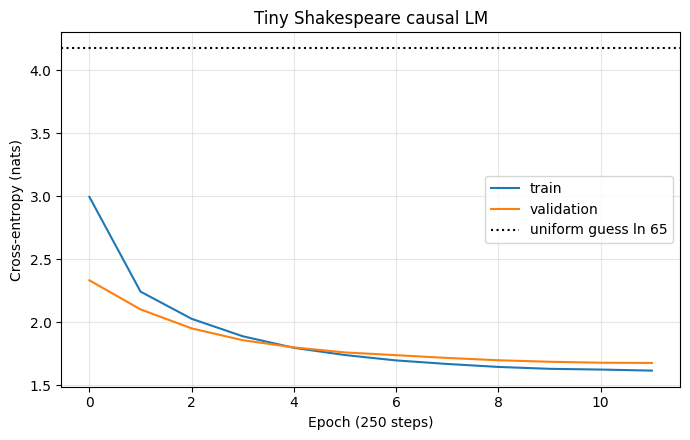

In [ ]:
# ---- test: causal LM ----
tm = CausalTransformerLM(17, ctx=16, d_model=32, heads=4, layers=2, d_ff=64, dropout=0.0).to(DEVICE)
xt = torch.randint(0, 17, (2, 8), device=DEVICE)
lg, ls, mp = tm(xt, xt, return_attention=True)
assert lg.shape == (2, 8, 17) and ls.ndim == 0 and all(torch.all(torch.triu(w, 1) == 0) for w in mp)
x1 = xt.clone(); x1[:, -1] = (x1[:, -1] + 1) % 17                    # changing the last token must not change earlier logits
tm.eval(); assert torch.allclose(tm(xt)[0][:, :-1], tm(x1)[0][:, :-1], atol=1e-5)
print("Causal LM tests PASSED")

@torch.no_grad()
def eval_lm(model, d, ctx, batch=64):
    """Validation loss (nats) over the WHOLE split using non-overlapping windows of length ctx."""
    model.eval(); n = (len(d) - 1) // ctx
    xs, ys = d[:n * ctx].view(n, ctx), d[1:n * ctx + 1].view(n, ctx); tot = 0.0
    for i in range(0, n, batch):
        x, y = xs[i:i + batch].to(DEVICE), ys[i:i + batch].to(DEVICE)
        tot += model(x, y)[1].item() * y.numel()
    return tot / (n * ctx)

def lr_factor(step, total, warm):
    if step < warm: return (step + 1) / warm
    p = (step - warm) / max(1, total - warm)
    return 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * p))

def train_lm(seed, causal=True, ctx=CONTEXT_LENGTH, heads=LM_HEADS, epochs=LM_EPOCHS, tag="main"):
    set_seed(seed)
    model = CausalTransformerLM(len(chars), ctx, LM_D_MODEL, heads, LM_LAYERS, LM_D_FF, LM_DROPOUT, causal).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LM_LR)
    total = epochs * LM_STEPS; sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: lr_factor(s, total, min(100, total // 10)))
    tr_c, va_c, secs = [], [], []
    for ep in range(epochs):
        model.train(); t0 = time.perf_counter(); losses = []
        for _ in range(LM_STEPS):
            x, y = get_batch(train_data, LM_BATCH, ctx)
            loss = model(x, y)[1]
            opt.zero_grad(set_to_none=True); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
            losses.append(loss.item())
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        secs.append(time.perf_counter() - t0); tr_c.append(float(np.mean(losses))); va_c.append(eval_lm(model, val_data, ctx))
        print(f"LM {tag} s{seed} ep {ep+1}/{epochs} train {tr_c[-1]:.4f} val {va_c[-1]:.4f} bpc {va_c[-1]/math.log(2):.4f}")
    val = va_c[-1]
    append_result(problem="P2_TaskB", model=f"Transformer_LM_{tag}", seed=seed, seq_len=ctx, params=count_parameters(model),
                  sec_per_epoch=float(np.mean(secs)), val_loss_nats=val, bits_per_char=val / math.log(2),
                  notes=f"d={LM_D_MODEL}; heads={heads}; layers={LM_LAYERS}; causal_mask={causal}; epochs={epochs}x{LM_STEPS} steps; batch={LM_BATCH}")
    return model, tr_c, va_c, val

lm, lm_tr, lm_va, lm_val = train_lm(SEEDS[0])
print(f"\nFinal validation loss {lm_val:.4f} nats = {lm_val/math.log(2):.4f} bits/char (uniform guess {math.log(len(chars)):.3f} nats)")
plt.figure(figsize=(7, 4.5)); plt.plot(lm_tr, label="train"); plt.plot(lm_va, label="validation")
plt.axhline(math.log(len(chars)), color="k", ls=":", label="uniform guess ln 65")
plt.xlabel("Epoch (%d steps)" % LM_STEPS); plt.ylabel("Cross-entropy (nats)"); plt.title("Tiny Shakespeare causal LM"); plt.legend(); plt.grid(alpha=.3)
savefig("p2_taskB_learning_curve.png")

In [ ]:
# ---- generated_samples.txt: 500 characters at temperature 0.2, 0.8, 1.5 (top-k = 20) ----
set_seed(SEEDS[0])
prompt = val_data[:40].view(1, -1).to(DEVICE)
with open("generated_samples.txt", "w", encoding="utf-8") as f:
    for temp in (0.2, 0.8, 1.5):
        gen = lm.generate(prompt.clone(), 500, temperature=temp, top_k=20)[0, -500:].tolist()
        sample = decode(gen)
        f.write(f"===== temperature {temp}, top-k 20, 500 characters =====\n{sample}\n\n")
        print(f"===== temperature {temp} =====\n{sample[:300]}\n")

===== temperature 0.2 =====
 the shall son,
And the brother of the shall be so man of the dead.

KING RICHARD III:
And the father of the stand of the consul of the man
The shall so the crown of the stand of the consul the crown.

CORIOLANUS:
What is the come of the son, when that the seems of the charge,
And with the confess o

===== temperature 0.8 =====
, if thou have being proves.

GLOUCESTER:
What words, must it be while seconing mine,
As charging the suppiers do both cousing of there,
I was and procee to canment: say wronged
To much at the ere time of the kings,
Should now, that I have is the world is with must of the good,
And the has the confu

===== temperature 1.5 =====
, majurhes alm.

CLIFFFORD:
Ay! Out, how you!

MARCIUS:
Whech is?
Your mether bd?

FRIAR LAURENCE:
As good or crering feel, I'll sha, he so.

GlOUT:
To loss e'elf. Farly facierious ye hour are.

CAMILLO:
Go. LYoUS:
Bother, fier!

CATES:
Execuse
Thought, though wwith upon us wipp and att
pliking of y



## 5(a) – Attention heatmaps for two heads on one sentence

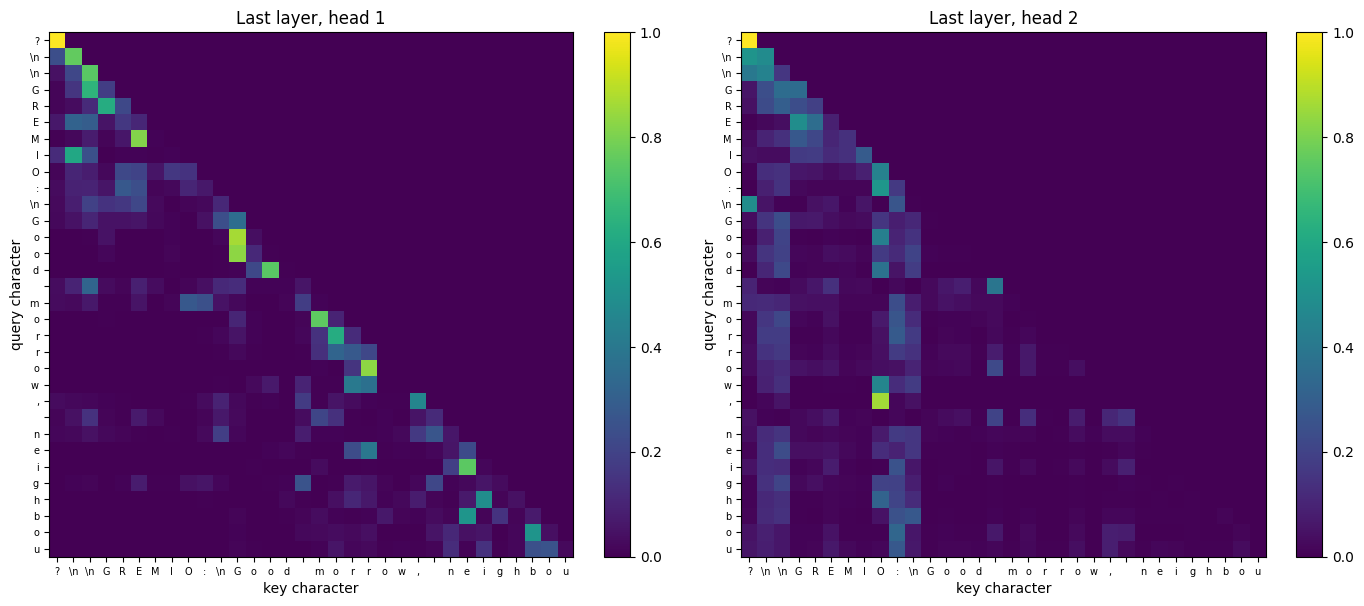

Sentence: '?\n\nGREMIO:\nGood morrow, neighbou'


In [ ]:
sentence = val_data[:32].view(1, -1).to(DEVICE)
lm.eval()
with torch.no_grad():
    _, _, maps = lm(sentence, return_attention=True)
labels = [c if c != "\n" else "\\n" for c in decode(sentence[0].tolist())]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, head in zip(axes, (0, 1)):
    im = ax.imshow(maps[-1][0, head].cpu().numpy(), cmap="viridis")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=7); ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=7)
    ax.set_xlabel("key character"); ax.set_ylabel("query character"); ax.set_title(f"Last layer, head {head+1}"); plt.colorbar(im, ax=ax, fraction=.046)
savefig("p2_attention_heatmaps.png")
print("Sentence:", repr(decode(sentence[0].tolist())))

## 5(b) – Heads = 1, 4, 8 at fixed d = 128

LM heads1 s11 ep 1/4 train 2.9918 val 2.3012 bpc 3.3200
LM heads1 s11 ep 2/4 train 2.2400 val 2.0947 bpc 3.0221
LM heads1 s11 ep 3/4 train 2.0794 val 2.0019 bpc 2.8881
LM heads1 s11 ep 4/4 train 2.0160 val 1.9703 bpc 2.8425
LM heads4 s11 ep 1/4 train 2.9952 val 2.3345 bpc 3.3680
LM heads4 s11 ep 2/4 train 2.2564 val 2.1175 bpc 3.0549
LM heads4 s11 ep 3/4 train 2.0866 val 2.0186 bpc 2.9122
LM heads4 s11 ep 4/4 train 2.0170 val 1.9859 bpc 2.8651
LM heads8 s11 ep 1/4 train 2.9979 val 2.3448 bpc 3.3828
LM heads8 s11 ep 2/4 train 2.2640 val 2.1332 bpc 3.0776
LM heads8 s11 ep 3/4 train 2.1018 val 2.0327 bpc 2.9326
LM heads8 s11 ep 4/4 train 2.0329 val 1.9952 bpc 2.8785
 heads  head_dim  val_loss_nats  bits_per_char
     1       128       1.970251       2.842471
     4        32       1.985907       2.865058
     8        16       1.995218       2.878492


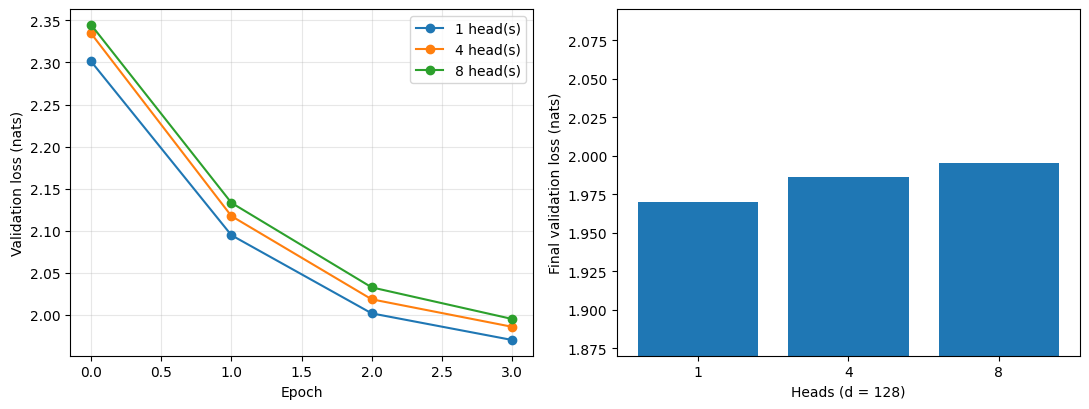

In [ ]:
head_rows, head_curves = [], {}
for hd in (1, 4, 8):
    _, tr, va, val = train_lm(SEEDS[0], heads=hd, epochs=ABL_EPOCHS, tag=f"heads{hd}")
    head_rows.append(dict(heads=hd, head_dim=LM_D_MODEL // hd, val_loss_nats=val, bits_per_char=val / math.log(2))); head_curves[hd] = (tr, va)
head_df = pd.DataFrame(head_rows); print(head_df.to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for hd, (tr, va) in head_curves.items(): ax[0].plot(va, marker="o", label=f"{hd} head(s)")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Validation loss (nats)"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].bar([str(h) for h in head_df.heads], head_df.val_loss_nats); ax[1].set_xlabel("Heads (d = 128)"); ax[1].set_ylabel("Final validation loss (nats)")
ax[1].set_ylim(head_df.val_loss_nats.min() - 0.1, head_df.val_loss_nats.max() + 0.1)
savefig("p2_heads_ablation.png")

## 5(c) – Remove the causal mask
Without the mask, position *t* can read the character at *t+1* that it must predict, so training loss collapses without the model learning to predict. We check this three ways: training/validation curves, the same model evaluated *with* the causal mask, and generated text.

LM with_mask s11 ep 1/4 train 2.9952 val 2.3345 bpc 3.3680
LM with_mask s11 ep 2/4 train 2.2564 val 2.1175 bpc 3.0549
LM with_mask s11 ep 3/4 train 2.0866 val 2.0186 bpc 2.9122
LM with_mask s11 ep 4/4 train 2.0170 val 1.9859 bpc 2.8651
LM no_mask s11 ep 1/4 train 2.9776 val 2.0689 bpc 2.9848
LM no_mask s11 ep 2/4 train 0.6675 val 0.0348 bpc 0.0503
LM no_mask s11 ep 3/4 train 0.0980 val 0.0260 bpc 0.0375
LM no_mask s11 ep 4/4 train 0.0773 val 0.0246 bpc 0.0354
                         model  final_train  val_nats   val_bpc
              with causal mask     2.017000  1.985907  2.865058
    no mask (val with leakage)     0.077286  0.024552  0.035420
no mask (val with causal mask)     0.077286  7.003238 10.103537


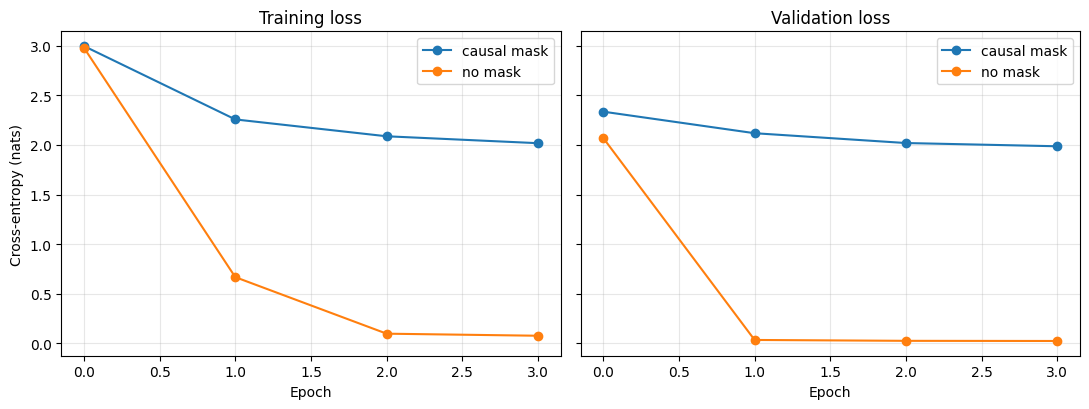

--- generation, with mask, T=0.8 ---
tety,
And wither way here dear to next she all and made
That from a with he stake hat fur be y faul excoland;
What that bot what not the with noth pot and to runce,
As and man ord up at of this crese of promen?

TOROMIO:
Al that the fam king be makey

--- generation, no mask, T=0.8 ---
ssssssssssssssssssssssssssssssssssssssssssssssssssssssssssssssssssssssssssssssssssssssss seseseseses s sesesesesesesesesesesys sesesesesesesessesesesesesssesesesessesesessesesesesesesssesessssesesesesssessesssesesesssesesssesesesesessesesesessssseses



In [ ]:
m_c, tr_c, va_c, val_c = train_lm(SEEDS[0], causal=True, epochs=ABL_EPOCHS, tag="with_mask")
m_n, tr_n, va_n, val_n = train_lm(SEEDS[0], causal=False, epochs=ABL_EPOCHS, tag="no_mask")
m_n.use_causal_mask = True                                           # evaluate the no-mask model the way it is used at generation time
val_n_causal = eval_lm(m_n, val_data, CONTEXT_LENGTH); m_n.use_causal_mask = False
print(pd.DataFrame([dict(model="with causal mask", final_train=tr_c[-1], val_nats=val_c, val_bpc=val_c / math.log(2)),
                    dict(model="no mask (val with leakage)", final_train=tr_n[-1], val_nats=val_n, val_bpc=val_n / math.log(2)),
                    dict(model="no mask (val with causal mask)", final_train=tr_n[-1], val_nats=val_n_causal, val_bpc=val_n_causal / math.log(2))]).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for a, (curve_c, curve_n, name) in zip(ax, [(tr_c, tr_n, "Training loss"), (va_c, va_n, "Validation loss")]):
    a.plot(curve_c, marker="o", label="causal mask"); a.plot(curve_n, marker="o", label="no mask"); a.set_title(name); a.set_xlabel("Epoch"); a.grid(alpha=.3); a.legend()
ax[0].set_ylabel("Cross-entropy (nats)"); savefig("p2_no_mask_result.png")
set_seed(SEEDS[0])
for name, mdl in (("with mask", m_c), ("no mask", m_n)):
    print(f"--- generation, {name}, T=0.8 ---\n" + decode(mdl.generate(prompt.clone(), 250, 0.8, 20)[0, -250:].tolist()) + "\n")

## 5(d) – Time and memory against context length (64, 128, 256, 512)
One forward + backward pass, batch 16. Peak memory is measured on GPU only (NaN on CPU).

 context  step_seconds  peak_mem_MB  attn_scores_per_layer  time_ratio_vs_64  n^2_ratio  n_ratio
      64        0.0104      86.2319                 262144            1.0000        1.0      1.0
     128        0.0102     133.8491                1048576            0.9767        4.0      2.0
     256        0.0188     267.4614                4194304            1.8066       16.0      4.0
     512        0.0532     712.4614               16777216            5.1067       64.0      8.0
log-log slope of time vs context: 0.79 (1 = linear, 2 = quadratic)


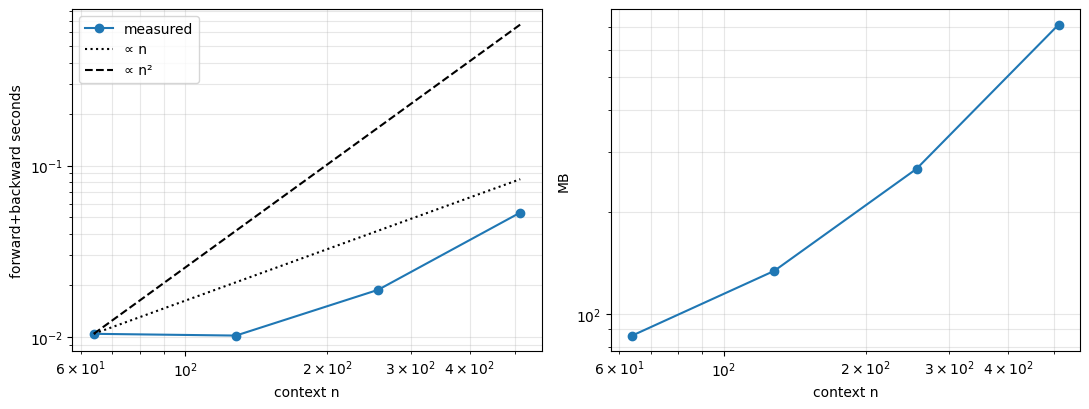

In [ ]:
rows = []
for ctx in (64, 128, 256, 512):
    mdl = CausalTransformerLM(len(chars), ctx, LM_D_MODEL, LM_HEADS, LM_LAYERS, LM_D_FF, 0.0).to(DEVICE).train()
    x = torch.randint(0, len(chars), (16, ctx), device=DEVICE)
    for _ in range(2): mdl(x, x)[1].backward(); mdl.zero_grad(set_to_none=True)             # warm-up
    if DEVICE.type == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    ts = []
    for _ in range(5 if QUICK_RUN else 15):
        t0 = time.perf_counter(); mdl(x, x)[1].backward()
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        ts.append(time.perf_counter() - t0); mdl.zero_grad(set_to_none=True)
    rows.append(dict(context=ctx, step_seconds=float(np.median(ts)),
                     peak_mem_MB=torch.cuda.max_memory_allocated() / 2**20 if DEVICE.type == "cuda" else float("nan"),
                     attn_scores_per_layer=16 * LM_HEADS * ctx * ctx))
    del mdl, x
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
sc = pd.DataFrame(rows)
sc["time_ratio_vs_64"] = sc.step_seconds / sc.step_seconds.iloc[0]; sc["n^2_ratio"] = (sc.context / 64) ** 2; sc["n_ratio"] = sc.context / 64
print(sc.round(4).to_string(index=False))
print(f"log-log slope of time vs context: {np.polyfit(np.log(sc.context), np.log(sc.step_seconds), 1)[0]:.2f} (1 = linear, 2 = quadratic)")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].loglog(sc.context, sc.step_seconds, "o-", label="measured")
ax[0].loglog(sc.context, sc.step_seconds.iloc[0] * sc["n_ratio"], "k:", label="∝ n"); ax[0].loglog(sc.context, sc.step_seconds.iloc[0] * sc["n^2_ratio"], "k--", label="∝ n²")
ax[0].set_xlabel("context n"); ax[0].set_ylabel("forward+backward seconds"); ax[0].legend(); ax[0].grid(alpha=.3, which="both")
if DEVICE.type == "cuda":
    ax[1].loglog(sc.context, sc.peak_mem_MB, "o-", label="peak GPU memory (MB)")
else:
    ax[1].text(0.1, 0.5, "peak GPU memory needs a GPU\n(attention scores ∝ n²: see table)", transform=ax[1].transAxes)
ax[1].set_xlabel("context n"); ax[1].set_ylabel("MB"); ax[1].grid(alpha=.3, which="both")
savefig("p2_time_memory_vs_context.png")

In [ ]:
res = pd.read_csv(RESULTS_CSV)
print("results.csv rows:", len(res), "| columns OK:", list(res.columns) == CSV_COLUMNS); print(res.groupby("problem").size())
print("Figures:", sorted(os.listdir(FIG_DIR)), "| generated_samples.txt:", os.path.exists("generated_samples.txt"))

results.csv rows: 15 | columns OK: True
problem
P2_TaskA    9
P2_TaskB    6
dtype: int64
Figures: ['p2_attention_heatmaps.png', 'p2_heads_ablation.png', 'p2_no_mask_result.png', 'p2_taskA_pos_ablation.png', 'p2_taskB_learning_curve.png', 'p2_time_memory_vs_context.png'] | generated_samples.txt: True
